# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')


In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum())
print()
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print()
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 --- 

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?  Valores nulos

Users

City (11.7%): nulos entre el 5% y el 30%. Los imputaría con "unknown", porque el dato es categórico y no se puede inferir. Además hay que tratar el centinela ?, que isna() no cuenta.
churn_date (88.4%): supera el 80%, pero no es un error: un vacío significa que el cliente sigue activo. Lo dejaría como nulo y, si hace falta, crearía una columna indicadora de baja (churned).

Usage

Date (0.125%): menos del 5%, un caso simple. Eliminaría esas 50 filas, porque una fecha no se puede inventar y representan una fracción mínima.
duration (55.2%) y length (44.7%): son nulos por diseño. Las llamadas solo tienen duración y los mensajes solo longitud. No los imputaría ni los eliminaría: analizaría llamadas y mensajes por separado.

plans no tiene nulos, así que no requiere acción.Valores nulos    

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [13]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(col)
    print(users[col].value_counts(dropna=False))
    print()


city
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

plan
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` ...
- La columna `plan` ...

In [15]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?                                                                        la columna users.age presenta un valor de -999 el cual seria mejor combertir en Nan e imputar con mediana; users.city presenta "?" y abreviaturas que prefeririamos pasar a "uknown" o nombres completos; usage posee 28 filas con duración y longitud a la vez de las cuales seria preferente dejar en NaN el campo que no corresponde al type; como ultimo el caso de usage duration y length, maneja Máximos muy altos, podrian revisarlos en el paso de outliers                                                                   

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.                            Aparecen los años 2022 (1,314), 2023 (1,316) y 2024 (1,330), con una distribución pareja. Pero hay 40 registros con año 2026 (1% de los usuarios). Como los datos están registrados hasta 2024, son fechas imposibles y se tratan como errores de captura.

In [19]:
users_2026 = users[users['reg_date'].dt.year == 2026]
print("Usuarios con reg_date 2026:", len(users_2026))
print("Registros de uso de esos usuarios:", usage['user_id'].isin(users_2026['user_id']).sum())

Usuarios con reg_date 2026: 40
Registros de uso de esos usuarios: 374


In [20]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`, ... haz doble clic en este bloque y escribe qué ves.                                Todos los 39,950 registros con fecha son de 2024, así que no hay años fuera de rango. Los únicos problemas son las 50 fechas ausentes ya detectadas.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?                                                                       ¿Aparecen años imposibles? Sí, en reg_date de users: hay 40 registros con año 2026 (1% de los usuarios). Como los datos están registrados hasta 2024, son fechas imposibles y se consideran errores de captura. En date de usage no aparecen años fuera de rango: los 39,950 registros con fecha son de 2024.

¿Qué haría con ellas? Convertiría esas 40 fechas a nulo (NaT) y conservaría a los usuarios. Esos 40 usuarios tienen 374 registros de uso en usage (alrededor del 0.9% del total), y esos registros son válidos. Eliminar al usuario dejaría esas llamadas y mensajes sin cliente asociado y perdería información útil. Solo la fecha de registro es el dato dañado.

Las 50 fechas ausentes de usage se eliminarían, porque son el 0.125% y una fecha no se puede inventar.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [21]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [22]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].isna().sum())
print((users['city'] == '?').sum())


565
0


In [23]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].isna().sum())
print(users['reg_date'].dt.year.value_counts().sort_index())


40
2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
print(usage['duration'].isna().groupby(usage['type']).mean())

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [25]:
# Verificación MAR en usage (Missing At Random) para length
print(usage['length'].isna().groupby(usage['type']).mean())

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`              
Los nulos dependen de la columna type. duration está vacía en casi todos los mensajes (text) y llena en las llamadas (call), y length muestra el patrón contrario. Como la ausencia se explica por otra variable observada (type), se confirma el patrón MAR.

Decisión: dejarlos como nulos. No son datos faltantes que se hayan perdido, sino un campo que no aplica según el tipo de evento: una llamada no tiene longitud de mensaje y un mensaje no tiene duración. Imputarlos inventaría información que no existe. Se analizarán llamadas y mensajes por separado.

Excepción: las 28 filas que tienen ambos valores llenos son inconsistentes y se revisarán por separado.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [26]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [28]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [29]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [30]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

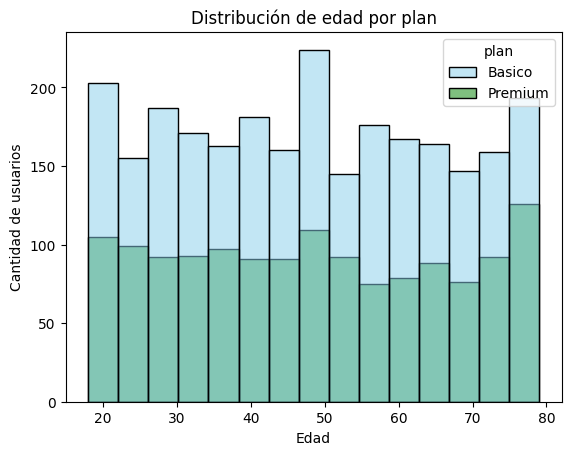

In [31]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=15)
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución: aproximadamente uniforme entre 18 y 80 años. No es campana ni está sesgada, ninguna franja de edad domina. Coincide con el boxplot, de bigotes a 18 y 80 y mediana cerca de 48.
Plan: Basico y Premium siguen la misma forma. Basico se ve más alto por tener casi el doble de usuarios, y Premium se mantiene en torno a un tercio en cada franja. La barra de los usuarios de mayor edad (≈76–80) parece la más alta de Premium, pero la diferencia es leve y no hay un patrón claro por plan.

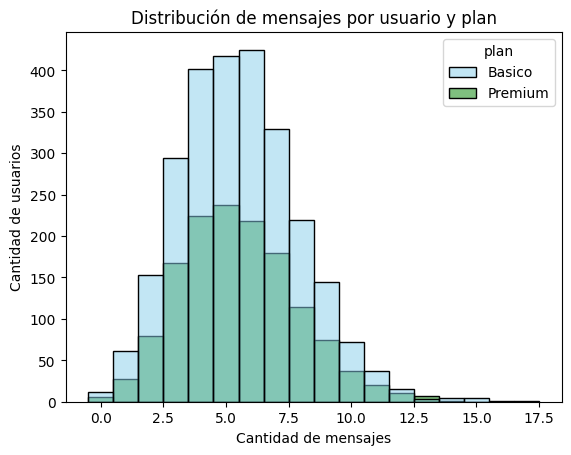

In [32]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de mensajes por usuario y plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución: forma de campana, casi simétrica, con una cola corta a la derecha que llega hasta unos 17 mensajes. La mayoría de los usuarios envía entre 3 y 7 mensajes, con el pico alrededor de 5. Coincide con el promedio de unos 5.5 que calculamos antes.
Plan: Basico y Premium tienen la misma forma y el mismo pico. Basico se ve más alto solo porque tiene casi el doble de usuarios (≈65% vs ≈35%). Las dos barras mantienen casi la misma proporción en cada valor (cerca de 420 contra 235 en el pico), así que no existe un patrón diferenciado por plan.

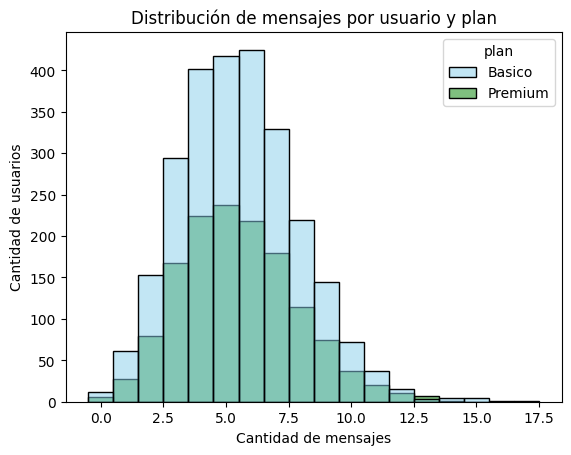

In [33]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de mensajes por usuario y plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución ...

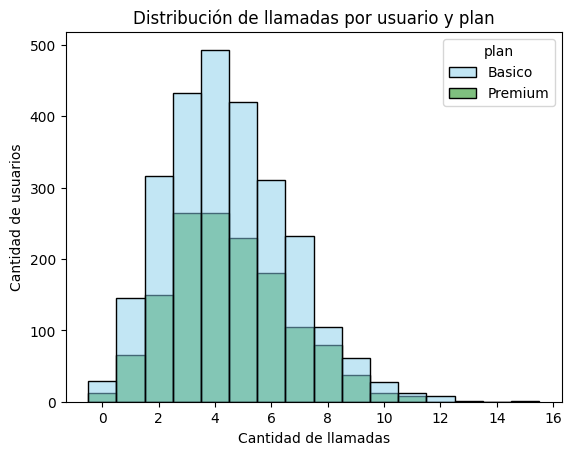

In [34]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de llamadas por usuario y plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Distribución: campana con el pico en 4 llamadas y una ligera cola a la derecha hasta unas 16. Es casi simétrica, con un sesgo a la derecha leve.
Plan: igual que en mensajes, la forma es la misma en los dos planes y la diferencia de altura se explica por el tamaño del grupo. No hay un patrón por plan.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

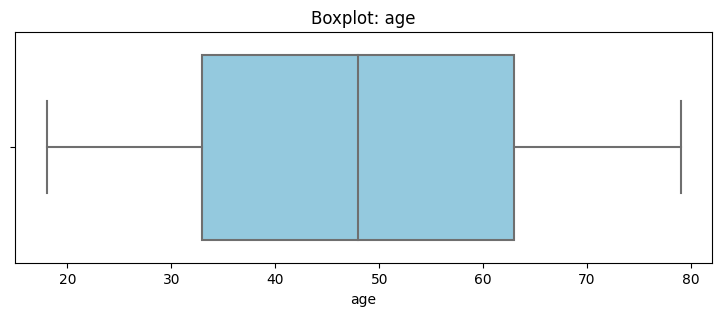

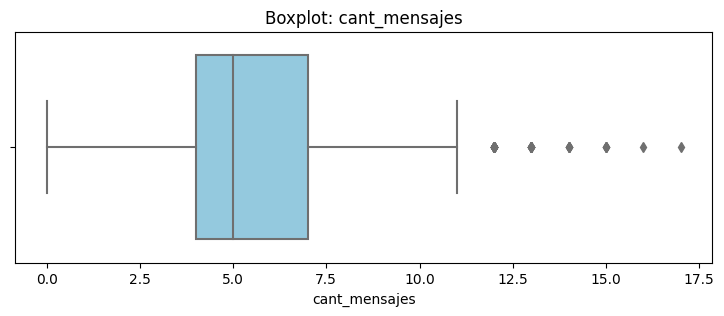

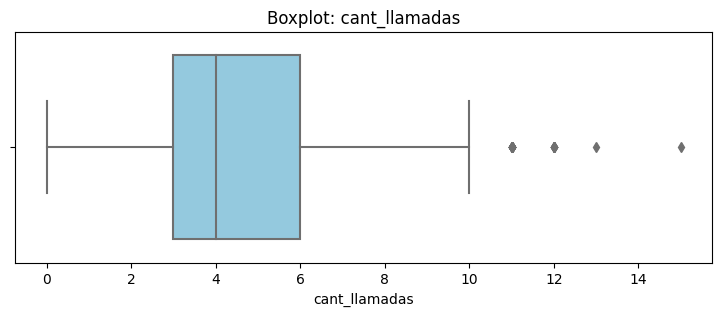

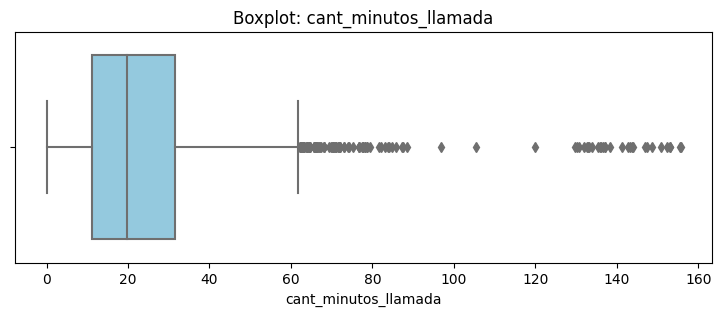

In [35]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [36]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    print(col, "→ límite superior:", upper, "| máximo:", user_profile[col].max(),
          "| usuarios por encima:", (user_profile[col] > upper).sum())


cant_mensajes → límite superior: 11.5 | máximo: 17.0 | usuarios por encima: 46
cant_llamadas → límite superior: 10.5 | máximo: 15.0 | usuarios por encima: 30
cant_minutos_llamada → límite superior: 61.8575 | máximo: 155.69 | usuarios por encima: 109


In [37]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_llamadas: mantener o no outliers, porqué?
- cant_minutos_llamada: mantener o no outliers, porqué?                                        Cant_minutos_llamada: mantener y marcar. El límite IQR es ≈ 61.9 minutos y hay 109 usuarios (≈ 2.7%) por encima. El máximo (155.7) se explica en buena parte por 30 llamadas de exactamente 120 minutos (el 0.17% de las llamadas). Esa repetición indica un tope del sistema o un valor por defecto, no un comportamiento natural.

Como son pocas y la fila entera es válida, no las eliminaría. Pero sus valores reales podrían ser mayores o estar distorsionados, así que las marcaría para revisión con el área de datos. Mientras tanto, usaría la mediana (19.8) y no la media (23.3) como referencia del uso típico, porque los extremos inflan el promedio. Si el análisis exigiera estabilizar la métrica, se capan al percentil 99.                                                                         Con mensajes y llamadas la decisión no cambia: se mantienen (máximos de 17 y 15, valores plausibles y cercanos a su límite).

In [38]:
print("Llamadas de exactamente 120 min:", (usage['duration'] == 120).sum())
print(usage['duration'].sort_values(ascending=False).head(10))
print("Usuarios por encima del límite:", (user_profile['cant_minutos_llamada'] > 61.86).sum())

Llamadas de exactamente 120 min: 30
38954    120.0
22814    120.0
23052    120.0
28921    120.0
20237    120.0
13235    120.0
27171    120.0
12921    120.0
1414     120.0
19360    120.0
Name: duration, dtype: float64
Usuarios por encima del límite: 109


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [39]:
# usuario sin registros de uso: su uso es 0, no desconocido
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

In [40]:
# Crear columna grupo_uso
user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where((user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio', 'Alto uso')
)


In [41]:
# verificar cambios
user_profile[['cant_mensajes', 'cant_llamadas', 'grupo_uso']].head()

,cant_mensajes,cant_llamadas,grupo_uso
0,7.0,3.0,Uso medio
1,5.0,10.0,Alto uso
2,5.0,2.0,Uso medio
3,11.0,3.0,Alto uso
4,4.0,3.0,Bajo uso


In [42]:
user_profile['grupo_uso'].value_counts(normalize=True) * 100

Uso medio    73.575
Bajo uso     19.475
Alto uso      6.950
Name: grupo_uso, dtype: float64

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [43]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(user_profile['age'] < 60, 'Adulto', 'Adulto Mayor')
)


In [44]:
# verificar cambios
user_profile[['age', 'grupo_edad']].head()

,age,grupo_edad
0,38.0,Adulto
1,53.0,Adulto
2,57.0,Adulto
3,69.0,Adulto Mayor
4,63.0,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

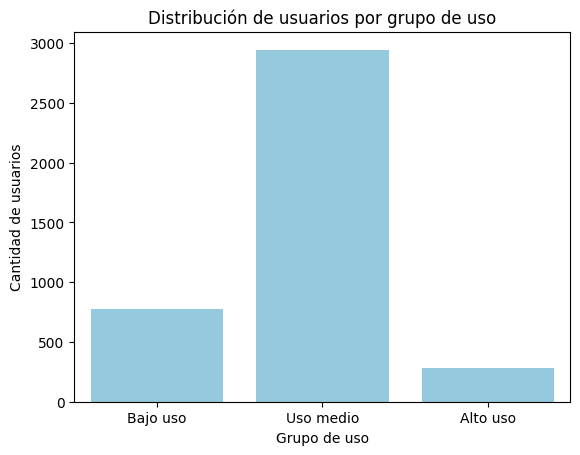

In [45]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

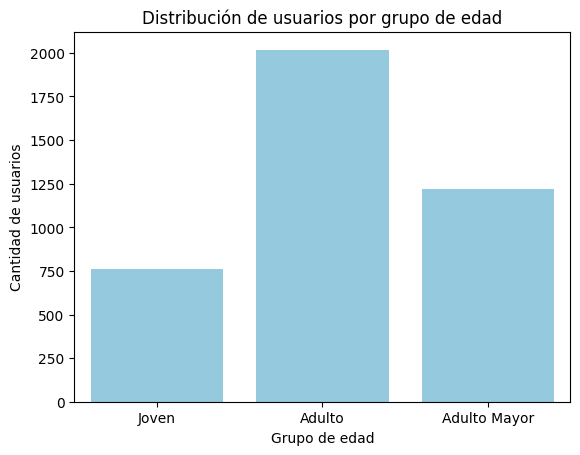

In [46]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [47]:
# Celda de apoyo para el insight ejecutivo
user_profile['churned'] = user_profile['churn_date'].notna()

print("Reparto por edad (%):")
print(user_profile['grupo_edad'].value_counts(normalize=True) * 100)
print("\nUso por grupo de edad (%):")
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100)
print("\nPromedios por grupo de edad:")
print(user_profile.groupby('grupo_edad')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean())
print("\nPromedios por plan:")
print(user_profile.groupby('plan')[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].mean())
print("\nBajas por plan (%):")
print(user_profile.groupby('plan')['churned'].mean() * 100)
print("\nBajas por grupo de uso (%):")
print(user_profile.groupby('grupo_uso')['churned'].mean() * 100)

# cantidad original de edades -999 (antes de reemplazarlas)
raw_users = pd.read_csv('/datasets/users_latam.csv')
print("\nEdades -999 originales:", (raw_users['age'] == -999).sum())

Reparto por edad (%):
Adulto          50.45
Adulto Mayor    30.55
Joven           19.00
Name: grupo_edad, dtype: float64

Uso por grupo de edad (%):
grupo_uso     Alto uso   Bajo uso  Uso medio
grupo_edad                                  
Adulto        7.581764  18.087215  74.331021
Adulto Mayor  6.055646  21.031097  72.913257
Joven         6.710526  20.657895  72.631579

Promedios por grupo de edad:
              cant_mensajes  cant_llamadas  cant_minutos_llamada
grupo_edad                                                      
Adulto             5.545590       4.480674             22.985263
Adulto Mayor       5.486088       4.502455             23.575974
Joven              5.522368       4.426316             23.751053

Promedios por plan:
         cant_mensajes  cant_llamadas  cant_minutos_llamada
plan                                                       
Basico        5.525626       4.454721             22.896609
Premium       5.518149       4.518149             24.077011

Bajas por


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

Análisis ejecutivo

⚠️ Problemas detectados en los datos

age: centinela -999 en 55 usuarios (1.4%), reemplazado por la mediana. Esos usuarios quedan clasificados como “Adulto” sin que su edad real se conozca.
city: 565 usuarios sin ciudad válida (14.1%): 469 vacíos (11.7%) y 96 con el centinela ? (2.4%). Además hay formatos mezclados (CDMX, GDL y MTY junto a nombres completos).
reg_date: 40 fechas de 2026 (1% de los usuarios), imposibles porque los datos llegan hasta 2024. Se marcaron como nulas y se conservó a los usuarios, que suman 374 registros de uso.
usage.date: 50 fechas vacías (0.125%).
duration y length: nulos por diseño (55.2% y 44.7%), según el tipo de evento. Además, 28 filas (0.07%) tienen ambos valores, una inconsistencia.
Duración de llamadas: 30 llamadas duran exactamente 120 minutos, lo que sugiere un tope del sistema.
Un usuario no tiene ningún registro de uso.

🔍 Segmentos por edad

La edad se reparte entre 18 y 80 años: Adulto 50.5% (30 a 59), Adulto Mayor 30.6% (60 o más) y Joven 19.0% (menos de 30).
El comportamiento de uso es prácticamente igual en los tres grupos: en promedio ≈ 5.5 mensajes, ≈ 4.5 llamadas y entre 23 y 24 minutos. La proporción de cada nivel de uso también es parecida (Uso medio entre 72.6% y 74.3%).

📊 Segmentos por nivel de uso

Uso medio concentra a la mayoría (73.6%, 2,943 usuarios), seguido de Bajo uso (19.5%, 779) y Alto uso (6.95%, 278).
Mensajes y llamadas tienen forma de campana, casi simétrica, y no cambian por plan: Basico y Premium se comportan igual. Premium solo usa ≈ 5% más minutos.

➡️ Esto sugiere que ni la edad ni el plan explican el nivel de uso. Los clientes se parecen mucho entre sí, así que segmentar ofertas solo por edad o por plan no capturaría diferencias reales de comportamiento.

💰 Segmentos más valiosos

Premium es el 35% de los usuarios, pero por cuota mensual aporta alrededor del 53% del ingreso (1,405 × 25 USD contra 2,595 × 12 USD, sin contar extras ni bajas). Es el segmento más valioso, y su tasa de bajas (12.0%) es similar a la de Basico (11.5%).
Alto uso (278 usuarios) es el segmento con más actividad y la mejor oportunidad de venta de capacidad adicional. Además, es el grupo con más bajas (14.0% contra ≈ 11.5%). Es una diferencia pequeña y con pocos usuarios, pero merece vigilarse porque se trata de los clientes más activos.

🚨 Uso extremo (outliers)

Mensajes y llamadas tienen pocos extremos (máximos de 17 y 15), que son comportamientos posibles y se mantienen.
En minutos, 109 usuarios (≈ 2.7%) superan el límite de 62 minutos. Parte del extremo se explica por el tope de 120 minutos, que conviene revisar con el área de datos. Para describir el uso típico, usar la mediana (19.8) y no la media (23.3).

💡 Recomendaciones

Revisar el valor percibido de Premium. Cuesta más del doble que Basico pero se usa casi igual. Hoy no hay más bajas en Premium, pero conviene reforzar lo que sí lo diferencia (por ejemplo los GB, que esta base no mide) antes de que el cliente note que no usa más.
Crear una acción de retención para los 278 usuarios de Alto uso, con ofertas de capacidad extra o beneficios de lealtad.
Segmentar con otras variables. Como la edad y el plan no separan comportamientos, probar con ciudad o país, antigüedad (reg_date) o consumo de datos.
Revisar los límites de los planes. Basico incluye 100 minutos y 100 mensajes, y el usuario típico consume una fracción. Si este uso es representativo, hay espacio para planes más económicos o con otro enfoque.
Corregir la calidad de datos en origen: ciudades faltantes y con formatos mezclados, fechas futuras, el tope de 120 minutos y los registros con duración y longitud a la vez.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`